# Stem-cell-only model

Stem cell only model (all basal cells are equipotent stem cells) with local density feedback

The figures aren't show in the paper, but the analysis is discussed in the Supplementary Note, but this is a limiting case of the SD model (r = 0.5, λ=Γ) which is studied there in detail.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../fit/")
sys.path.append("../../plot/")

import clones

import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)


from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 10
#rcParams['axes.labelweight'] = 'bold'
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] = 7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 7.5  # General font size
rcParams['text.usetex'] = False
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 1.5
rcParams['lines.linewidth']  = 1.0



def get_bootstrap_ci(bootstrap_samples, axis=0, confidence=0.95):
    """
    Calculate confidence intervals from bootstrap samples along a specified axis.
    
    Parameters:
    -----------
    bootstrap_samples : array-like
        3D array of bootstrap samples where:
        - First dimension is the number of bootstrap samples
        - Second and third dimensions are your original 2D data shape
    axis : int, default=0
        The axis of the original 2D data along which to calculate CIs
        0 = calculate CI for each column
        1 = calculate CI for each row
    confidence : float, default=0.95
        Confidence level (0 to 1)
        
    Returns:
    --------
    tuple
        (lower_bounds, upper_bounds, means)
        Each is an array corresponding to the CIs and means along the specified axis
    """
    # Convert input to numpy array if it isn't already
    samples = np.asarray(bootstrap_samples)
    
    # Calculate alpha for confidence interval
    alpha = (1 - confidence) / 2
    
    # Calculate percentiles and mean along the bootstrap samples dimension
    # Add 1 to axis because original axis 0/1 is now 1/2 due to bootstrap dimension
    lower_bounds = np.nanpercentile(samples, alpha * 100, axis=0)
    upper_bounds = np.nanpercentile(samples, (1 - alpha) * 100, axis=0)
    means = np.mean(samples, axis=0)
    
    # If axis=0 (columns), we want stats for each column of original data
    # If axis=1 (rows), we want stats for each row of original data
    if axis == 0:
        return lower_bounds, upper_bounds, means
    elif axis == 1:
        return (lower_bounds.T, upper_bounds.T, means.T)
    else:
        raise ValueError("Axis must be 0 or 1")

def exp2simSkippedTimes(texp, tscale, tshift = 0, skip = 10):
    if np.ndim(texp) == 0:
        return int((texp + tshift)*tscale/skip)
    else:
        return ((texp + tshift)*tscale/skip).astype('int32')



In [ ]:
# Run simulation

import tiss_optimize as topt
import sim_model

L = 32
i = 0
tsteps = -50

s0 = topt.simulator(sim_model.S_mech_switch, {'tau': [1000, 100], #[50, 100, 500, 1000, 5000], 
                                               'hilln': [32,0.5],#[0.5, 2, 8, 16, 32],
                                               'p0': [3.0, 4.0],
                                               'cv_div': [1.0]}, 
                    params = {'r': 1.0, 'L': L, 'useTerm': False}, 
                    simtype = 'h')

s0.run_sim(ncells = L**2, tsteps = tsteps, seeds = np.arange(1), savefolder = 'S_mech_switch/',
            tscalevals = 1, use_saved_metrics = False, ncores = 1, skip = -0.1, 
            init_params = {'relaxsteps': 2500, 'homeosteps': 20000}, i = i)

In [ ]:
# Load simulation data
sim_folder = 'S_mech_switch/'
cv = 1.0
hilln = 32.0
tau = 50.0
sim_file = f'hrun_S_mech_switch_t_-100_n_1024_L_32_cv_div_{cv}_hilln_{hilln}_p0_3.0_r_1.0_tau_{tau}_useTerm_False_seed_0.pkl'

results = load_object(sim_folder + '/' + sim_file)
tiss = results['tiss']
# Get clone size distributions
ca_sim = clones.sanalysis(results, popnames = ['D', 'S'], skip = results['skip'], containsBasal=True)

/tmp/ipykernel_127011/408626134.py:17: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.load(outp)
/tmp/ipykernel_127011/408626134.py:17: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case

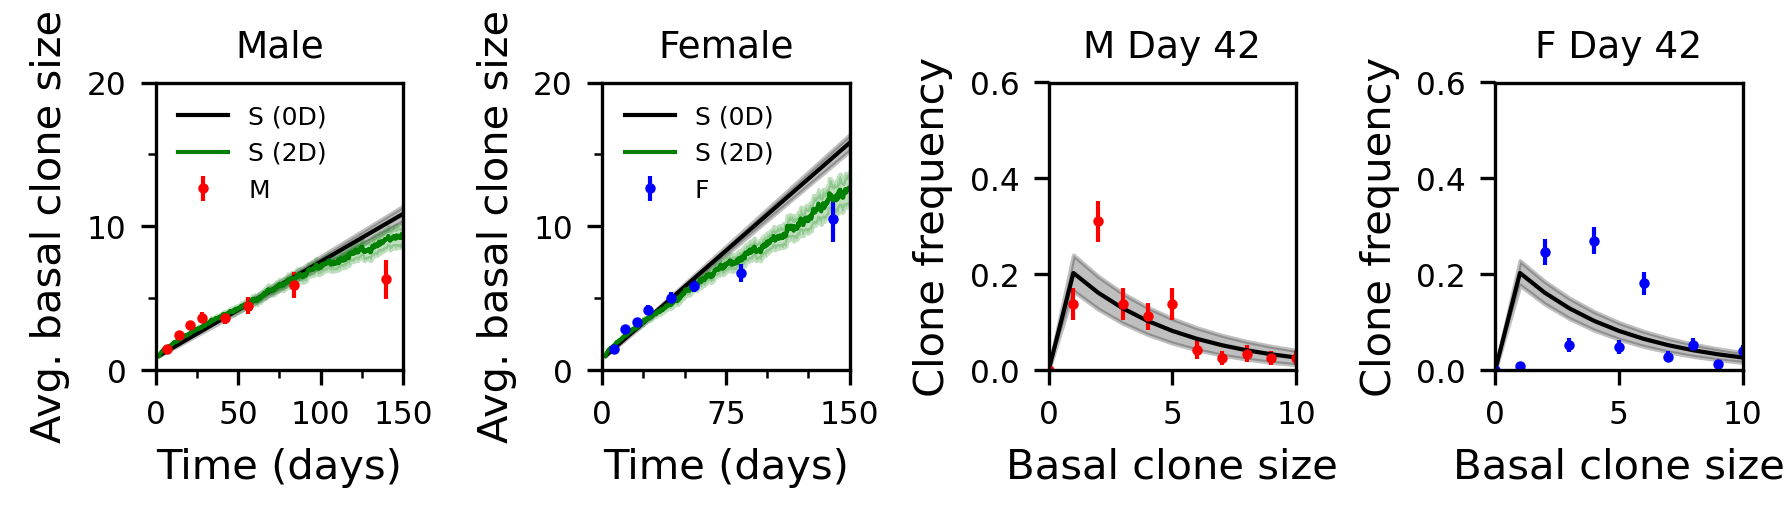

In [ ]:
nboots = 5000
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']

col = {'M': 'r', 'F': 'b'}
conf = 0.68

tfull = np.linspace(0,150, 1000)
tau = 15
dx = 2
tau2d = 22


fig, axes = plt.subplots(1, 4, figsize=(1.5*4,1.75), dpi=300)
for sex in ['M']:
    exp_data = load_object(exp_folder + f'data_ctr_{sex}.pkl')
    livesize = exp_data['livesize']
    # Subplot 1: Average Clone Size
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    db = clone_anal.boot('av_bas_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    axes[0].errorbar(clone_anal.tvals, clone_anal.av_bas_cs, upper68-lower68, fmt=f'{col[sex]}o', label=f'{sex}')
    db = clone_anal.boot('av_tot_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    #axes[0].errorbar(clone_anal.tvals, clone_anal.av_tot_cs, upper68-lower68, fmt=f'{col[sex]}^', label=f'{sex} Total')
se_bas_theory = np.sqrt((tfull/tau)*(1+tfull/tau)/exp_data['nallc'][0])
axes[0].plot(tfull+dx, 1 + tfull/tau, 'k-', label = 'S (0D)')
axes[0].fill_between(tfull+2, ((1 + tfull/tau) - se_bas_theory), np.ones(len(tfull))*((1 + tfull/tau) + se_bas_theory), color = 'k', alpha = 0.25)
se_bas_theory = np.sqrt((tfull/tau)*(1+tfull/tau)/exp_data['nallc'][0])
axes[0].plot(2+ca_sim.tvals/tau2d, ca_sim.av_bas_cs, 'g-', label = 'S (2D)')
#se_theory = ca_sim.boot('av_bas_cs')  # ca_sim.se_bas_cs
se_theory = ca_sim.se_bas_cs
axes[0].fill_between(2+ca_sim.tvals/tau2d, (ca_sim.av_bas_cs - se_theory), (ca_sim.av_bas_cs + se_theory), color = 'g', alpha = 0.25)
#axes[0].plot(tfull+dx, 1 + tfull/tau1, 'k--', label = 'S model: Total')
#axes[0].fill_between(tfull+2, ((1 + tfull/tau1) - se_bas_theory), np.ones(len(tfull))*((1 + tfull/tau1) + se_bas_theory), color = 'k', alpha = 0.25)
axes[0].set_xlabel('Time (days)')
axes[0].set_ylabel('Avg. basal clone size')
#axes[0].set_ylabel('Average clone size')
axes[0].legend(frameon=False, fontsize=6, loc='upper left')
axes[0].set_ylim([0, 20])
axes[0].set_yticks(np.arange(0, 21, 10))
axes[0].set_yticks(np.arange(0, 21, 5), minor=True)
axes[0].set_xlim([0, 150])
axes[0].set_xticks(np.arange(0, 151, 50))
axes[0].set_xticks(np.arange(0, 151, 25), minor=True)
axes[0].set_title('Male')



dx = 2
tau = 10
tau2d = 30

for sex in ['F']:
    exp_data = load_object(exp_folder + f'data_ctr_{sex}.pkl')
    livesize = exp_data['livesize']
    # Subplot 1: Average Clone Size
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    db = clone_anal.boot('av_bas_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    axes[1].errorbar(clone_anal.tvals, clone_anal.av_bas_cs, upper68-lower68, fmt=f'{col[sex]}o', label=f'{sex}')
    db = clone_anal.boot('av_tot_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    #axes[0].errorbar(clone_anal.tvals, clone_anal.av_tot_cs, upper68-lower68, fmt=f'{col[sex]}^', label=f'{sex} Total')
se_bas_theory = np.sqrt((tfull/tau)*(1+tfull/tau)/exp_data['nallc'][0])
axes[1].plot(tfull+dx, 1 + tfull/tau, 'k-', label = 'S (0D)')
axes[1].fill_between(tfull+2, ((1 + tfull/tau) - se_bas_theory), np.ones(len(tfull))*((1 + tfull/tau) + se_bas_theory), color = 'k', alpha = 0.25)
axes[1].plot(2+ca_sim.tvals/tau2d, ca_sim.av_bas_cs, 'g-', label = 'S (2D)')
#se_theory = ca_sim.boot('av_bas_cs')  # ca_sim.se_bas_cs
se_theory = ca_sim.se_bas_cs
axes[1].fill_between(2+ca_sim.tvals/tau2d, (ca_sim.av_bas_cs - se_theory), (ca_sim.av_bas_cs + se_theory), color = 'g', alpha = 0.25)
axes[1].set_xlabel('Time (days)')
axes[1].set_ylabel('Avg. basal clone size')
#axes[0].set_ylabel('Average clone size')
axes[1].legend(frameon=False, fontsize=6, loc='upper left')
axes[1].set_ylim([0, 20])
axes[1].set_yticks(np.arange(0, 21, 10))
axes[1].set_yticks(np.arange(0, 21, 5), minor=True)
axes[1].set_xlim([0, 150])
axes[1].set_xticks(np.arange(0, 151, 75))
axes[1].set_xticks(np.arange(0, 151, 25), minor=True)
axes[1].set_title('Female')


pdf_2d = ca_sim.bas_pdf()
    
tau0ds = {'M': 15, 'F': 15}
tau2ds = {'M': 150, 'F': 100}

tfull = np.linspace(0,90, 1000)
tvals = exp_data['ctrTimeClonesize']  

times = tvals
subtimes = [4]
dxx = 2
for sex in ['M', 'F']:
    tau = tau0ds[sex]
    tau2d = tau2ds[sex]

    exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    bas_pdf = clone_anal.bas_pdf()
    av_bas_ctr = exp_data['ctrBasalsize']

    #for t in range(len(subtimes)):
    t = 0
    xx = t
    X = (times[subtimes[t]] + dx)/tau + 1
    xvals = np.arange(0,21)
    prob = 1/(1+X)*(X/(1+X))**(xvals-1)
    prob[0] = 0
    se_prob = np.sqrt(prob*(1-prob)/clone_anal.nsamples[subtimes[t]])
    t2d = exp2simSkippedTimes(subtimes[t], tau2d, 2, results['skip'])
    
    axes[xx+dxx].errorbar(np.arange(bas_pdf.shape[1]), bas_pdf[subtimes[t],:].T, clone_anal.bootpdf('bas_pdf', 1000, 'se')[subtimes[t],:bas_pdf.shape[1]], fmt='o', color = col[sex], label = f'{sex}')
    axes[xx+dxx].plot(xvals, prob, color = 'k', linestyle = '-', label = 'S model (0D)')
    axes[xx+dxx].fill_between(xvals, prob - se_prob, prob + se_prob, color = 'k', alpha = 0.25, label = '__nolegend__')
    #axes[xx+dxx].plot(xvals, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)], color = 'g', linestyle = '-', label = 'S model (2D)')
    #se_prob = np.sqrt(prob*(1-prob)/clone_anal.nsamples[subtimes[t]])
    #axes[xx+dxx].fill_between(xvals, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)] - se_prob, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)] + se_prob, color = 'g', alpha = 0.25, label = '__nolegend__')
    axes[xx+dxx].set_xlabel('Basal clone size')
    axes[xx+dxx].set_ylabel('Clone frequency')          
    axes[xx+dxx].set_xlim([0, 10])
    if t == 0:
        axes[xx+dxx].set_ylim([0, 0.6])     
    else:
        axes[xx+dxx].set_ylim([0, 0.25])     
    axes[xx+dxx].set_title(f'{sex} Day {int(times[subtimes[t]])}')

    t = 1

    if t >= len(subtimes):
        dxx += 1
        continue

    xx = t
    X = (times[subtimes[t]] + dx)/tau + 1
    xvals = np.arange(0,21)
    prob = 1/(1+X)*(X/(1+X))**(xvals-1)
    prob[0] = 0
    se_prob = np.sqrt(prob*(1-prob)/clone_anal.nsamples[subtimes[t]])
    t2d = exp2simSkippedTimes(subtimes[t], tau2d, 2, results['skip'])
    
    axes[xx+dxx].errorbar(np.arange(bas_pdf.shape[1]), bas_pdf[subtimes[t],:].T, clone_anal.bootpdf('bas_pdf', 1000, 'se')[subtimes[t],:bas_pdf.shape[1]], fmt='o', color = col[sex], label = f'{sex}')
    axes[xx+dxx].plot(xvals, prob, color = 'k', linestyle = '-', label = 'S model (0D)')
    axes[xx+dxx].fill_between(xvals, prob - se_prob, prob + se_prob, color = 'k', alpha = 0.25, label = '__nolegend__')
    #axes[xx+dxx].plot(xvals, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)], color = 'g', linestyle = '-', label = 'S model (2D)')
    #se_prob = np.sqrt(prob*(1-prob)/clone_anal.nsamples[subtimes[t]])
    #axes[xx+dxx].fill_between(xvals, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)] - se_prob, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)] + se_prob, color = 'g', alpha = 0.25, label = '__nolegend__')
    axes[xx+dxx].set_xlabel('Basal clone size')
    axes[xx+dxx].set_ylabel('Clone frequency')         
    axes[xx+dxx].set_xlim([0, 20])
    axes[xx+dxx].set_ylim([0, 0.4])        
    axes[xx+dxx].set_title(f'{sex} Day {int(times[subtimes[t]])}')
    dxx += 2
    
plt.tight_layout()
plt.savefig('Figures/SFig3_Smodel/S_model_Fig.pdf', bbox_inches='tight')
plt.show()  what 


In [ ]:
#95ci

nboots = 5000
exp_folder = '../../experiment/2410_Dan/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']

col = {'M': 'r', 'F': 'b'}
conf = 0.95

tfull = np.linspace(0,150, 1000)
tau = 15
dx = 2
tau2d = 22


fig, axes = plt.subplots(1, 4, figsize=(1.5*4,1.75), dpi=300)
for sex in ['M']:
    exp_data = load_object(exp_folder + f'data_ctr_{sex}.pkl')
    livesize = exp_data['livesize']
    # Subplot 1: Average Clone Size
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    db = clone_anal.boot('av_bas_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    axes[0].errorbar(clone_anal.tvals, clone_anal.av_bas_cs, upper68-lower68, fmt=f'{col[sex]}o', label=f'{sex}')
    db = clone_anal.boot('av_tot_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    #axes[0].errorbar(clone_anal.tvals, clone_anal.av_tot_cs, upper68-lower68, fmt=f'{col[sex]}^', label=f'{sex} Total')
se_bas_theory = np.sqrt((tfull/tau)*(1+tfull/tau)/exp_data['nallc'][0])
axes[0].plot(tfull+dx, 1 + tfull/tau, 'k-', label = 'S (0D)')
axes[0].fill_between(tfull+2, ((1 + tfull/tau) - se_bas_theory), np.ones(len(tfull))*((1 + tfull/tau) + se_bas_theory), color = 'k', alpha = 0.25)
se_bas_theory = np.sqrt((tfull/tau)*(1+tfull/tau)/exp_data['nallc'][0])*1.96
axes[0].plot(2+ca_sim.tvals/tau2d, ca_sim.av_bas_cs, 'g-', label = 'S (2D)')
#se_theory = ca_sim.boot('av_bas_cs')  # ca_sim.se_bas_cs
se_theory = ca_sim.se_bas_cs*1.96
axes[0].fill_between(2+ca_sim.tvals/tau2d, (ca_sim.av_bas_cs - se_theory), (ca_sim.av_bas_cs + se_theory), color = 'g', alpha = 0.25)
#axes[0].plot(tfull+dx, 1 + tfull/tau1, 'k--', label = 'S model: Total')
#axes[0].fill_between(tfull+2, ((1 + tfull/tau1) - se_bas_theory), np.ones(len(tfull))*((1 + tfull/tau1) + se_bas_theory), color = 'k', alpha = 0.25)
axes[0].set_xlabel('Time (days)')
axes[0].set_ylabel('Avg. basal clone size')
#axes[0].set_ylabel('Average clone size')
axes[0].legend(frameon=False, fontsize=6, loc='upper left')
axes[0].set_ylim([0, 20])
axes[0].set_yticks(np.arange(0, 21, 10))
axes[0].set_yticks(np.arange(0, 21, 5), minor=True)
axes[0].set_xlim([0, 150])
axes[0].set_xticks(np.arange(0, 151, 50))
axes[0].set_xticks(np.arange(0, 151, 25), minor=True)
axes[0].set_title('Male')



dx = 2
tau = 10
tau2d = 30

for sex in ['F']:
    exp_data = load_object(exp_folder + f'data_ctr_{sex}.pkl')
    livesize = exp_data['livesize']
    # Subplot 1: Average Clone Size
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    db = clone_anal.boot('av_bas_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    axes[1].errorbar(clone_anal.tvals, clone_anal.av_bas_cs, upper68-lower68, fmt=f'{col[sex]}o', label=f'{sex}')
    db = clone_anal.boot('av_tot_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    #axes[0].errorbar(clone_anal.tvals, clone_anal.av_tot_cs, upper68-lower68, fmt=f'{col[sex]}^', label=f'{sex} Total')
se_bas_theory = np.sqrt((tfull/tau)*(1+tfull/tau)/exp_data['nallc'][0])
axes[1].plot(tfull+dx, 1 + tfull/tau, 'k-', label = 'S (0D)')
axes[1].fill_between(tfull+2, ((1 + tfull/tau) - se_bas_theory), np.ones(len(tfull))*((1 + tfull/tau) + se_bas_theory), color = 'k', alpha = 0.25)
axes[1].plot(2+ca_sim.tvals/tau2d, ca_sim.av_bas_cs, 'g-', label = 'S (2D)')
#se_theory = ca_sim.boot('av_bas_cs')  # ca_sim.se_bas_cs
se_theory = ca_sim.se_bas_cs*1.96
axes[1].fill_between(2+ca_sim.tvals/tau2d, (ca_sim.av_bas_cs - se_theory), (ca_sim.av_bas_cs + se_theory), color = 'g', alpha = 0.25)
axes[1].set_xlabel('Time (days)')
axes[1].set_ylabel('Avg. basal clone size')
#axes[0].set_ylabel('Average clone size')
axes[1].legend(frameon=False, fontsize=6, loc='upper left')
axes[1].set_ylim([0, 20])
axes[1].set_yticks(np.arange(0, 21, 10))
axes[1].set_yticks(np.arange(0, 21, 5), minor=True)
axes[1].set_xlim([0, 150])
axes[1].set_xticks(np.arange(0, 151, 75))
axes[1].set_xticks(np.arange(0, 151, 25), minor=True)
axes[1].set_title('Female')


pdf_2d = ca_sim.bas_pdf()
    
tau0ds = {'M': 15, 'F': 15}
tau2ds = {'M': 150, 'F': 100}

tfull = np.linspace(0,90, 1000)
tvals = exp_data['ctrTimeClonesize']  

times = tvals
subtimes = [4]
dxx = 2
for sex in ['M', 'F']:
    tau = tau0ds[sex]
    tau2d = tau2ds[sex]

    exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    bas_pdf = clone_anal.bas_pdf()
    av_bas_ctr = exp_data['ctrBasalsize']

    #for t in range(len(subtimes)):
    t = 0
    xx = t
    X = (times[subtimes[t]] + dx)/tau + 1
    xvals = np.arange(0,21)
    prob = 1/(1+X)*(X/(1+X))**(xvals-1)
    prob[0] = 0
    se_prob = np.sqrt(prob*(1-prob)/clone_anal.nsamples[subtimes[t]])
    t2d = exp2simSkippedTimes(subtimes[t], tau2d, 2, results['skip'])
    
    axes[xx+dxx].errorbar(np.arange(bas_pdf.shape[1]), bas_pdf[subtimes[t],:].T, clone_anal.bootpdf('bas_pdf', 1000, 'se')[subtimes[t],:bas_pdf.shape[1]], fmt='o', color = col[sex], label = f'{sex}')
    axes[xx+dxx].plot(xvals, prob, color = 'k', linestyle = '-', label = 'S model (0D)')
    axes[xx+dxx].fill_between(xvals, prob - se_prob, prob + se_prob, color = 'k', alpha = 0.25, label = '__nolegend__')
    #axes[xx+dxx].plot(xvals, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)], color = 'g', linestyle = '-', label = 'S model (2D)')
    #se_prob = np.sqrt(prob*(1-prob)/clone_anal.nsamples[subtimes[t]])
    #axes[xx+dxx].fill_between(xvals, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)] - se_prob, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)] + se_prob, color = 'g', alpha = 0.25, label = '__nolegend__')
    axes[xx+dxx].set_xlabel('Basal clone size')
    axes[xx+dxx].set_ylabel('Clone frequency')          
    axes[xx+dxx].set_xlim([0, 10])
    if t == 0:
        axes[xx+dxx].set_ylim([0, 0.6])     
    else:
        axes[xx+dxx].set_ylim([0, 0.25])     
    axes[xx+dxx].set_title(f'{sex} Day {int(times[subtimes[t]])}')

    t = 1

    if t >= len(subtimes):
        dxx += 1
        continue

    xx = t
    X = (times[subtimes[t]] + dx)/tau + 1
    xvals = np.arange(0,21)
    prob = 1/(1+X)*(X/(1+X))**(xvals-1)
    prob[0] = 0
    se_prob = np.sqrt(prob*(1-prob)/clone_anal.nsamples[subtimes[t]])*1.96
    t2d = exp2simSkippedTimes(subtimes[t], tau2d, 2, results['skip'])
    
    axes[xx+dxx].errorbar(np.arange(bas_pdf.shape[1]), bas_pdf[subtimes[t],:].T, clone_anal.bootpdf('bas_pdf', 1000, 'se')[subtimes[t],:bas_pdf.shape[1]], fmt='o', color = col[sex], label = f'{sex}')
    axes[xx+dxx].plot(xvals, prob, color = 'k', linestyle = '-', label = 'S model (0D)')
    axes[xx+dxx].fill_between(xvals, prob - se_prob, prob + se_prob, color = 'k', alpha = 0.25, label = '__nolegend__')
    #axes[xx+dxx].plot(xvals, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)], color = 'g', linestyle = '-', label = 'S model (2D)')
    #se_prob = np.sqrt(prob*(1-prob)/clone_anal.nsamples[subtimes[t]])
    #axes[xx+dxx].fill_between(xvals, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)] - se_prob, pdf_2d[t2d,xvals[0]:(xvals[-1]+1)] + se_prob, color = 'g', alpha = 0.25, label = '__nolegend__')
    axes[xx+dxx].set_xlabel('Basal clone size')
    axes[xx+dxx].set_ylabel('Clone frequency')         
    axes[xx+dxx].set_xlim([0, 20])
    axes[xx+dxx].set_ylim([0, 0.4])        
    axes[xx+dxx].set_title(f'{sex} Day {int(times[subtimes[t]])}')
    dxx += 2
    
plt.tight_layout()
#plt.savefig('Figures/SFig3_Smodel/S_model_Fig.pdf', bbox_inches='tight')
plt.show()  
